# Lab 3

### Setup
Load the libraries and dataset.

In [9]:
%pip install numpy matplotlib scipy scikit-learn pandas jupyterlab ipywidgets seaborn kagglehub --quiet

Note: you may need to restart the kernel to use updated packages.


In [10]:
import kagglehub
import os
import pandas as pd


# Download latest version
path = kagglehub.dataset_download(
    "nikhil7280/student-performance-multiple-linear-regression"
)
df = pd.read_csv(os.path.join(path, "Student_Performance.csv"))
print(df.info())

# Impute NaN values with column mean
numerical_cols = df.select_dtypes(include=["number"]).columns
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].mean())

# Encode categorical columns into enums
categorical_cols = df.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    df[col] = df[col].astype("category").cat.codes

target_col = "Performance Index"
X = df.drop(columns=[target_col])
y = df[target_col]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB
None


### Split the dataset & preprocess
Split the dataset into training, testing and validation sets.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Split the dataset into training (70%), validation (15%), and testing (15%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Normalize features (analogous to calculating z-scores without magnitude)
# Calculates mean, std on training set, applies to all sets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

### Decision Tree Building

In [12]:
# Import regressor because target is continuous (float)
from sklearn.tree import DecisionTreeRegressor
import numpy as np


def build_decision_tree(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    max_depth: int | None = None,
):
    clf = DecisionTreeRegressor(
        max_depth=max_depth,
        random_state=42,
        # Disable pruning to see overfitting
        ccp_alpha=0,
    )
    clf.fit(X_train, y_train)
    return clf, clf.score(X_test, y_test), clf.score(X_val, y_val)

### Predicting target feature and analyzing noise impact on training

Plotting decision trees...
Best Depth: 9
Most Overfit Depth: 1


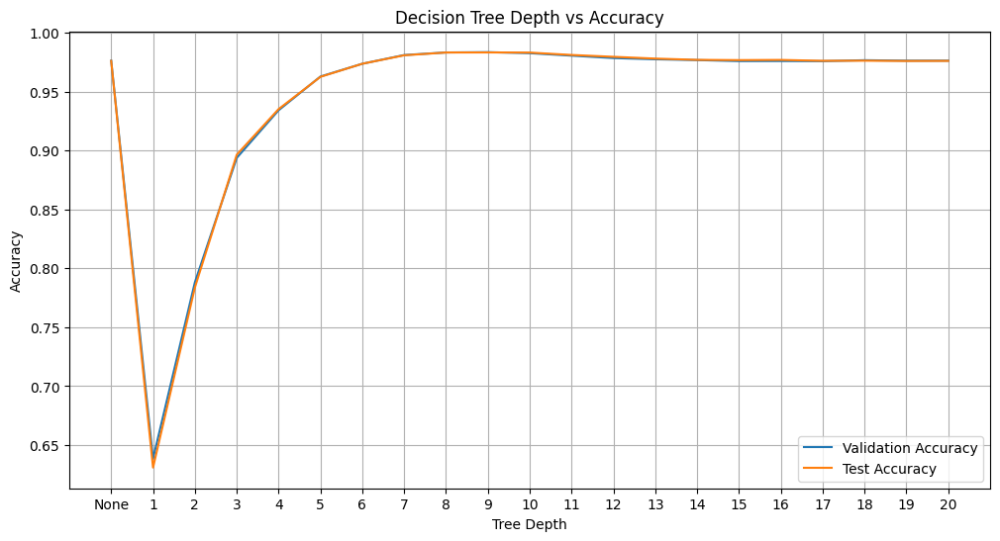

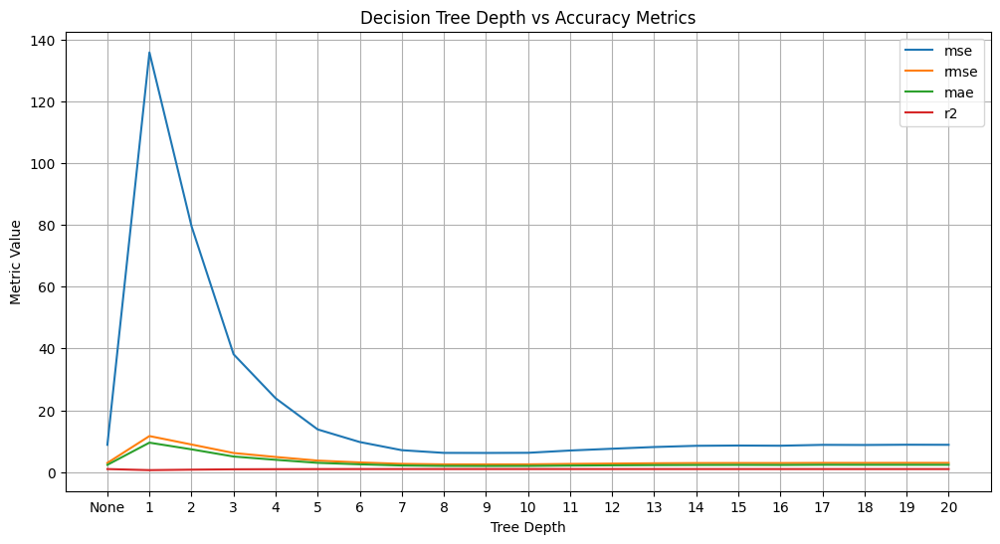

Plotting decision trees with noise...
Best Depth: 9
Most Overfit Depth: 2


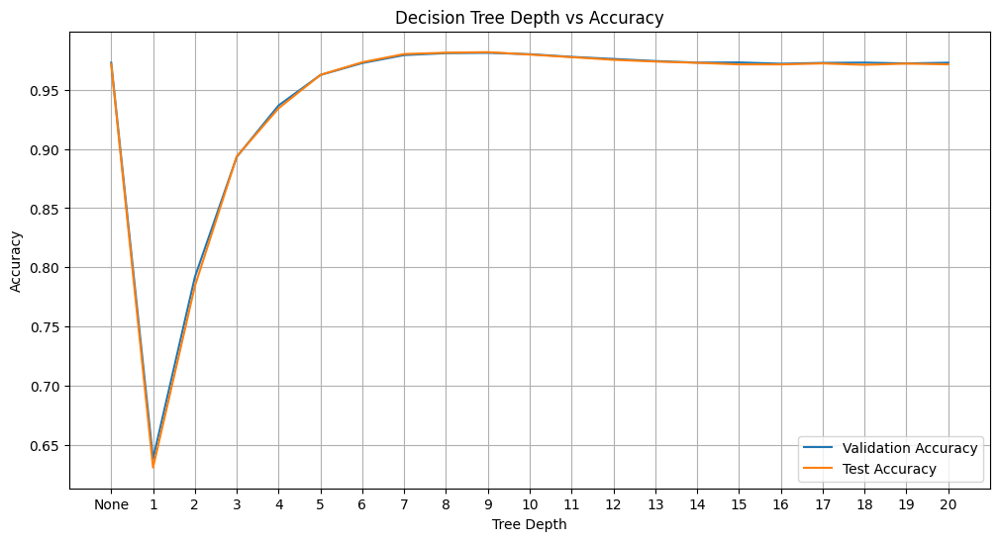

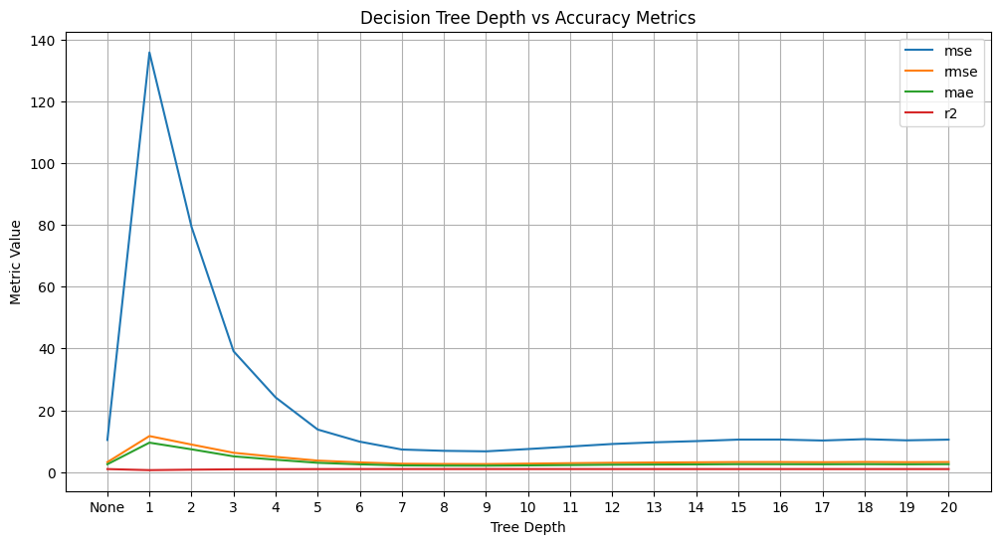

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import plot_tree

depth, val_acc, test_acc = "Depth", "Validation Accuracy", "Test Accuracy"


def plot_trees(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
):
    depths = np.concatenate(([None], np.arange(1, 21)))  # type: ignore
    models = np.array(
        [
            build_decision_tree(
                X_train, y_train, X_val, y_val, X_test, y_test, max_depth=mode
            )
            for mode in depths
        ]
    )

    mse = np.array([np.mean((y_test - model.predict(X_test))**2) for model, _, _ in models])
    # Visualize the results
    results = pd.DataFrame(
        {
            depth: depths.astype(str),  # better for categorical x-axis
            val_acc: np.array([val for _, _, val in models]),
            test_acc: np.array([test for _, test, _ in models]),
            'mse': mse,
            'rmse': np.sqrt(mse),
            'mae': np.array([np.mean(np.abs(y_test - model.predict(X_test))) for model, _, _ in models]),
            'r2': np.array([test for _, test, _ in models]),
        }
    )

    # Print top depth
    best_tree_idx = results[test_acc].idxmax()
    best_depth = results.loc[best_tree_idx]
    print(f"Best Depth: {best_depth[depth]}")

    # Print most overfitted depth
    results["overfit"] = results[val_acc] - results[test_acc]
    most_overfit_idx = results["overfit"].idxmax()
    most_overfit_depth = results.loc[most_overfit_idx]
    print(f"Most Overfit Depth: {most_overfit_depth[depth]}")

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=results, x=depth, y=val_acc, label=val_acc)
    sns.lineplot(data=results, x=depth, y=test_acc, label=test_acc)
    plt.title("Decision Tree Depth vs Accuracy")
    plt.xlabel("Tree Depth")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

    # Visualize the best tree
    best_model = models[best_tree_idx][0]
    plt.figure(figsize=(480, 64))
    plot_tree(best_model, filled=True, feature_names=X.columns.to_list(), fontsize=16)
    plt.title("Best Decision Tree")
    plt.show()

    # Visualize accuracy metrics
    accuracy_metrics = ['mse', 'rmse', 'mae', 'r2']
    plt.figure(figsize=(12, 6))
    for metric in accuracy_metrics:
        sns.lineplot(data=results, x=depth, y=metric, label=metric)
    plt.title("Decision Tree Depth vs Accuracy Metrics")
    plt.xlabel("Tree Depth")
    plt.ylabel("Metric Value")
    plt.legend()
    plt.grid()
    plt.show()


print("Plotting decision trees...")
plot_trees(X_train, y_train, X_val, y_val, X_test, y_test)

# Adding some noise to see if it helps with overfitting
generator = np.random.default_rng(42)
X_train_noisy = X_train + generator.uniform(-0.1, 0.1, X_train.shape)
print("Plotting decision trees with noise...")
plot_trees(X_train_noisy, y_train, X_val, y_val, X_test, y_test)

### Denoise using Singular Value Decomposition (SVD)

Variance of original test set: [1.02445954 1.0095791  1.00447548]
Variance of noisy test set: [1.0295036  1.01320552 1.0063724 ]
MSE between original and noisy: 0.0033
MSE between original and denoised: 0.3943


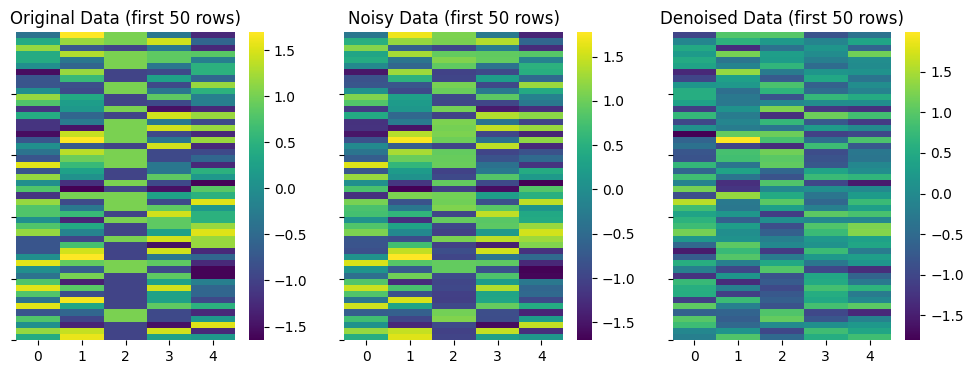

In [14]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

def fit_svd(X, k):
    svd = TruncatedSVD(n_components=k, random_state=42)
    svd.fit(X)
    return svd

k = 3

svd_orig, svd_noisy = fit_svd(X_train, k), fit_svd(X_train_noisy, k)
print(f"Variance of original test set: {svd_orig.explained_variance_}")
print(f"Variance of noisy test set: {svd_noisy.explained_variance_}")

X_train_denoised = svd_noisy.inverse_transform(svd_noisy.transform(X_train_noisy))

mse_noisy = mean_squared_error(X_train, X_train_noisy)
mse_denoised = mean_squared_error(X_train, X_train_denoised)
print(f"MSE between original and noisy: {mse_noisy:.4f}")
print(f"MSE between original and denoised: {mse_denoised:.4f}")

_, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, data in enumerate([X_train, X_train_noisy, X_train_denoised]):
    sns.heatmap(data[:50], cmap="viridis", ax=axes[i])
    axes[i].set_title(f'{["Original", "Noisy", "Denoised"][i]} Data (first 50 rows)')
    axes[i].set_yticks(range(10, 51, 10))
plt.show()

### Build Decision Tree on denoised data

Plotting decision trees with denoised data...
Best Depth: 4
Most Overfit Depth: 20


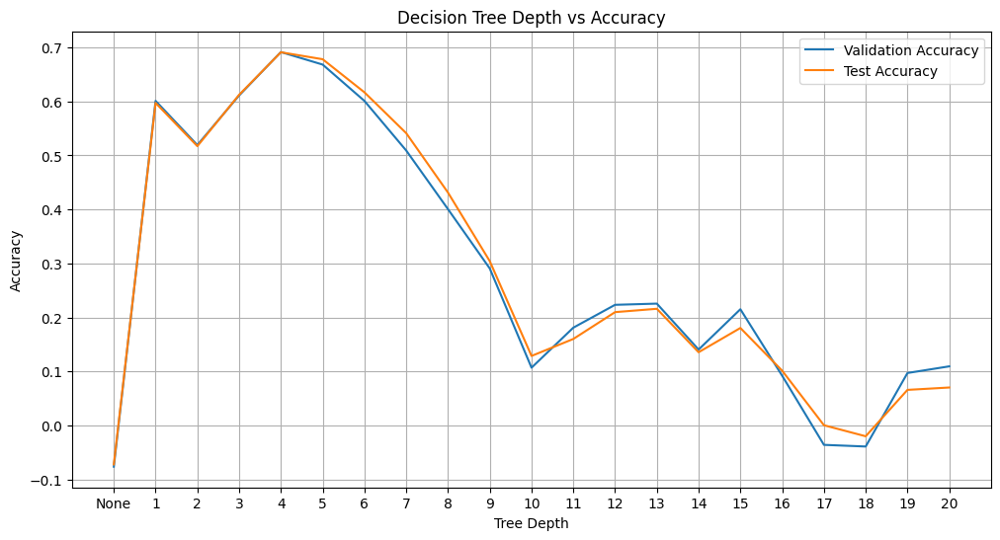

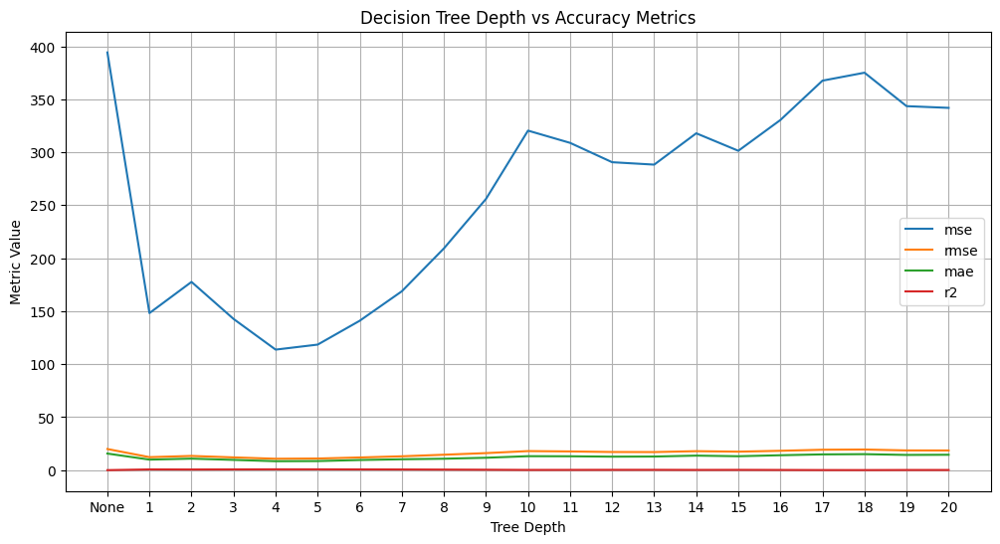

In [15]:
print("Plotting decision trees with denoised data...")
plot_trees(X_train_denoised, y_train, X_val, y_val, X_test, y_test)